# Lab 8


## Setup for SUSY Dataset

Use the SUSY dataset for the rest of this lab. Here is a basic setup. It reads the full file you downloaded in Lab 7 (5 million rows, about 760 MB in memory once loaded). If your computer struggles, read `../Lab.7/SUSY-small.csv` instead (the first 500,000 rows) and divide the sample sizes below by ten.

`RawNames` are the 8 quantities measured directly; `FeatureNames` are the 10 derived from them, which the physicists designed to separate signal from background. You will need both in Exercise 3.

In [1]:
# Our usual libraries...
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import HTML, display
import tabulate

In [2]:
filename="../Lab.7/SUSY.csv"
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", 
          "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET",
          "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=[v for v in VarNames[1:] if v not in RawNames]
df = pd.read_csv(filename, dtype='float64', names=VarNames)

In [4]:
df.head(5)

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859


## Scikit-Learn

[Scikit-learn](https://scikit-learn.org) is a rich python library for data science, including machine learning. For example, we can build a Fisher Discriminant (aka Linear Discriminant Analysis, or LDA). 

### Exercise 1: Install Scikit-Learn

`scikit-learn` is in the course `requirements.txt`, so it should already be in your environment: check that `import sklearn` works. If it doesn't, follow the [Installation Instructions](https://scikit-learn.org/stable/install.html).

In [6]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 50.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scikit-learn] [scikit-learn]

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [7]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


### Exercise 2: Read About Classifiers

#### Part a
Scikit-learn offers an impressively comprehensive list of machine learning algorithms. Browse through [scikit-learn's documentation](https://scikit-learn.org/stable/index.html). You'll note the algorithms are organized into classification, regression, clustering, dimensionality reduction, model selection, and preprocessing. Browse through the list of [classification algorithms](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning). 

#### Part b
Note scikit-learn's documentation is rather comprehensive. The documentation on [linear models](https://scikit-learn.org/stable/modules/linear_model.html) shows how classification problems are setup. Read about the first few methods and try to comprehend the example codes. Skim the rest of the document.

#### Part c
Read through the [LDA Documentation](https://scikit-learn.org/stable/modules/lda_qda.html).


### Exercise 3: Training a Classifier

Let's repeat what we did by hand in the previous lab (Lab 7, Exercise 8) using scikit-learn. We'll use an LDA classifier, which we can instantiate as follows:

In [8]:
import sklearn.discriminant_analysis as DA
Fisher=DA.LinearDiscriminantAnalysis()

As discussed in the lecture, to properly formulate our problem, we'll have to:

* Define the inputs (X) vs outputs (Y)
* Designate training vs testing samples (in order to get an unbiased assessment of the performance of machine learning algorithms)

For example, here we'll use 4M events for training and the remainder for testing.

In [9]:
N_Train=4000000

Train_Sample=df[:N_Train]
Test_Sample=df[N_Train:]

X_Train=Train_Sample[VarNames[1:]]
y_Train=Train_Sample["signal"]

X_Test=Test_Sample[VarNames[1:]]
y_Test=Test_Sample["signal"]

Test_sig=Test_Sample[Test_Sample.signal==1]
Test_bkg=Test_Sample[Test_Sample.signal==0]


We can train the classifier as follows:

In [10]:
Fisher.fit(X_Train,y_Train)

,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide <array_api>` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None
Name,Type,Value
"classes_ classes_: array-like of shape (n_classes,)Unique class labels.","ndarray[float64](2,)","[0.,1.]"
"coef_ coef_: ndarray of shape (n_features,) or (n_classes, n_features)Weight vector(s).","ndarray[float64](1, 18)","[[ 1.11,-0. ,-0. ,..., 0.86,-0.04, 2.58]]"
"explained_variance_ratio_ explained_variance_ratio_: ndarray of shape (n_components,)Percentage of variance explained by each of the selected components.If ``n_components`` is not set then all components are stored and thesum of explained variances is equal to 1.0. Only available when eigenor svd solver is used.","ndarray[float64](1,)",[1.]


We can plot the output, comparing signal and background:

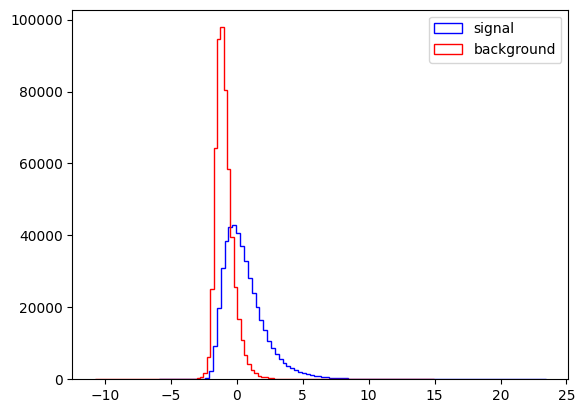

In [6]:
plt.figure()
plt.hist(Fisher.decision_function(Test_sig[VarNames[1:]]),bins=100,histtype="step", color="blue", label="signal",stacked=True)
plt.hist(Fisher.decision_function(Test_bkg[VarNames[1:]]),bins=100,histtype="step", color="red", label="background",stacked=True)
plt.legend(loc='upper right')
plt.show()

#### Part a

Compare the ROC curves computed on the test and on the training samples, in a single plot. Do you see a bias? (Use `Fisher.decision_function` on each sample, and `roc_curve` as in Exercise 5.)

In [12]:
from sklearn.metrics import roc_curve, roc_auc_score

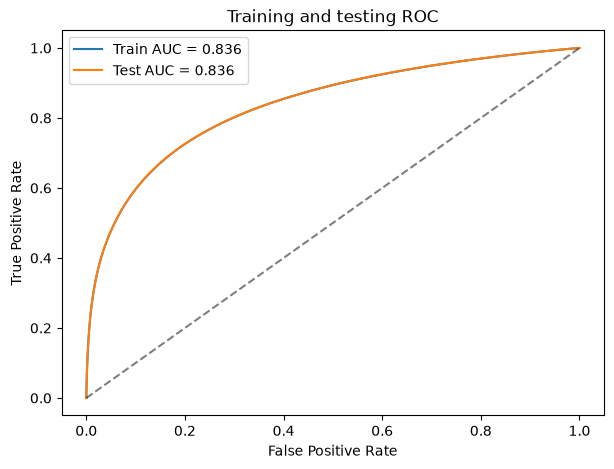

In [13]:
train_scores = Fisher.decision_function(X_Train)
test_scores = Fisher.decision_function(X_Test)
fpr_train, tpr_train, _ = roc_curve(y_Train, train_scores)
fpr_test, tpr_test, _ = roc_curve(y_Test, test_scores)
plt.figure(figsize=(7, 5))
plt.plot(fpr_train, tpr_train, label=f"Train AUC = {roc_auc_score(y_Train, train_scores):.3f}")
plt.plot(fpr_test, tpr_test, label=f"Test AUC = {roc_auc_score(y_Test, test_scores):.3f}")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Training and testing ROC")
plt.legend()
plt.show()


#### Part b

Train three Fisher discriminants, using as input (1) only the raw quantities (`RawNames`), (2) only the derived features (`FeatureNames`), and (3) all 18. Compare their ROC curves, computed on the test sample, in a single plot. Which inputs carry the separation?

In [16]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

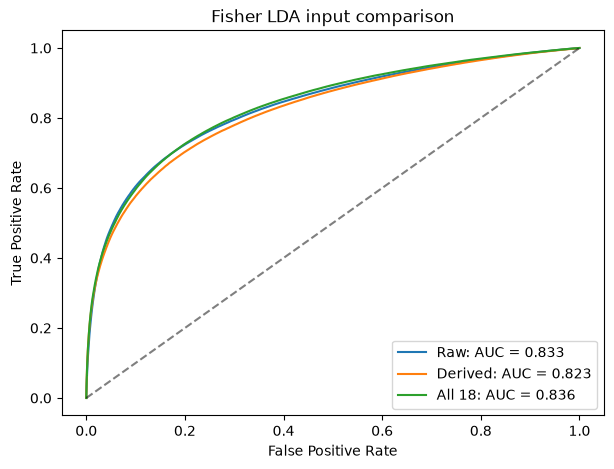

Highest test AUC: All 18


In [17]:
AllNames = VarNames[1:]
feature_sets = {
    "Raw": RawNames,
    "Derived": FeatureNames,
    "All 18": AllNames
}

plt.figure(figsize=(7, 5))
lda_results = {}
for label, columns in feature_sets.items():
    model = LinearDiscriminantAnalysis()
    model.fit(Train_Sample[columns], y_Train)
    scores = model.decision_function(Test_Sample[columns])
    auc_value = roc_auc_score(y_Test, scores)
    lda_results[label] = auc_value
    fpr, tpr, _ = roc_curve(y_Test, scores)
    plt.plot(fpr, tpr, label=f"{label}: AUC = {auc_value:.3f}")

plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Fisher LDA input comparison")
plt.legend()
plt.show()

print("Highest test AUC:", max(lda_results, key=lda_results.get))

### Exercise 4: Comparing Techniques

#### Part a
Select 3 different classifiers from the techniques listed [here](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning) to compare. Note that you can use the multi-layer perceptron to build a deep network, though training may be prohibitively slow. So avoid this technique.

#### Part b

Write a function that takes an instantiated classifier and performs the comparison from Exercise 3b. Use the function on each of the classifiers you chose in part a.

#### Part c

Use the best method from part b to compute the maximal significance $\sigma_S= \frac{N_S}{\sqrt{N_S+N_B}}$ for the four scenarios in Lab 7 (Exercise 5.3), choosing the cut on the classifier's output that maximizes it.

In [24]:
# Part a : I choose Logistic Regression, Gaussian Naive Bayes, and Random Forest. 

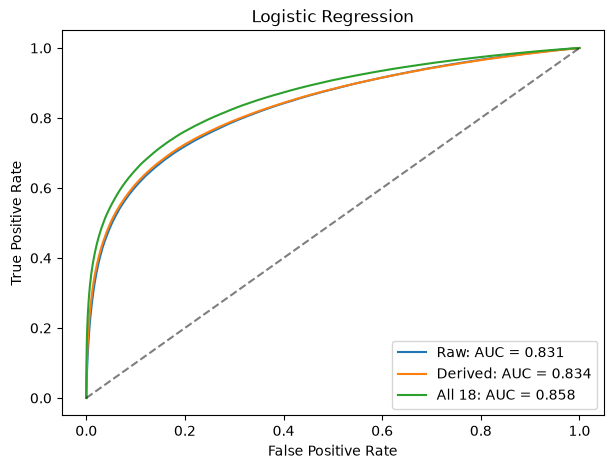

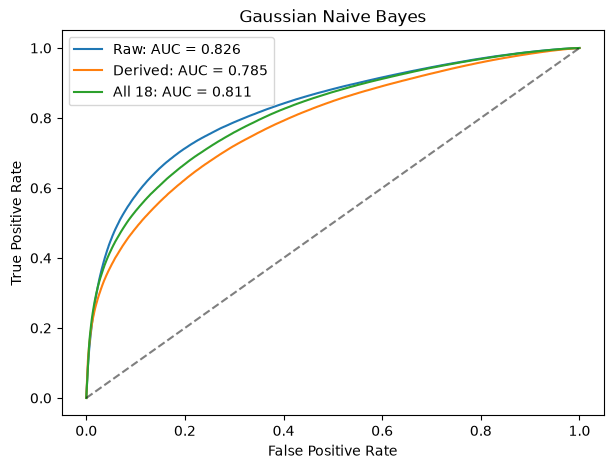

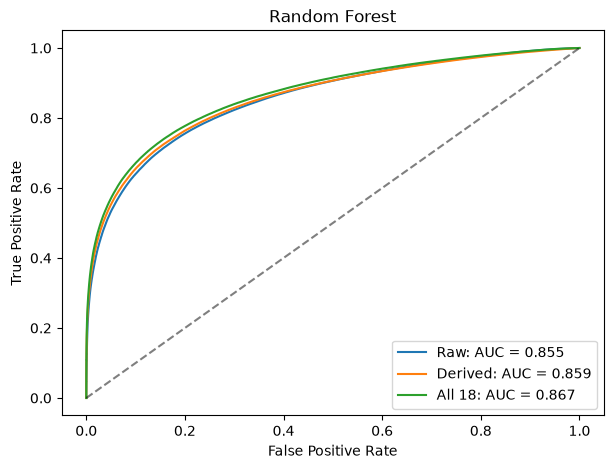

,Method,Inputs,AUC
0,Logistic Regression,Raw,0.8312
1,Logistic Regression,Derived,0.8335
2,Logistic Regression,All 18,0.8580
3,Gaussian Naive Bayes,Raw,0.8262
4,Gaussian Naive Bayes,Derived,0.7854
5,Gaussian Naive Bayes,All 18,0.8110
6,Random Forest,Raw,0.8549
7,Random Forest,Derived,0.8588
8,Random Forest,All 18,0.8675


Best method: Random Forest
Best input set: All 18
Best AUC: 0.8675


In [28]:
# Part b
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

train_for_models = Train_Sample.iloc[:min(100000, len(Train_Sample))]
y_train_models = train_for_models["signal"].astype(int)
models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Gaussian Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=60, max_depth=12,
                                            random_state=42, n_jobs=-1)
}

def compare_classifier(model, name):
    from sklearn.base import clone
    rows = []
    plt.figure(figsize=(7, 5))
    for label, columns in feature_sets.items():
        clf = clone(model)
        clf.fit(train_for_models[columns], y_train_models)
        scores = clf.predict_proba(Test_Sample[columns])[:, 1]
        fpr, tpr, _ = roc_curve(y_Test, scores)
        auc_value = roc_auc_score(y_Test, scores)
        rows.append({"Method": name, "Inputs": label, "AUC": auc_value})
        plt.plot(fpr, tpr, label=f"{label}: AUC = {auc_value:.3f}")

    plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(name)
    plt.legend()
    plt.show()
    return rows

all_results = []
for name, model in models.items():
    all_results.extend(compare_classifier(model, name))

results_table = pd.DataFrame(all_results)
display(results_table.round(4))

best_row = results_table.loc[results_table["AUC"].idxmax()]
print("Best method:", best_row["Method"])
print("Best input set:", best_row["Inputs"])
print("Best AUC:", round(best_row["AUC"], 4))

In [29]:
# Part c

from sklearn.base import clone

scenarios = [(10, 100), (100, 1000), (1000, 10000), (10000, 100000)]
best_name = best_row["Method"]
best_inputs = best_row["Inputs"]
best_columns = feature_sets[best_inputs]
split = int(len(train_for_models) * 0.8)
fit_data = train_for_models.iloc[:split]
valid_data = train_for_models.iloc[split:]
best_model = clone(models[best_name])
best_model.fit(fit_data[best_columns], fit_data["signal"].astype(int))
valid_y = valid_data["signal"].astype(int)
valid_scores = best_model.predict_proba(valid_data[best_columns])[:, 1]
test_scores_best = best_model.predict_proba(Test_Sample[best_columns])[:, 1]

valid_fpr, valid_tpr, valid_thresholds = roc_curve(valid_y, valid_scores)

def significance(signal_eff, background_eff, expected_signal, expected_background):
    s = signal_eff * expected_signal
    b = background_eff * expected_background
    return np.divide(s, np.sqrt(s + b), out=np.zeros_like(np.asarray(s, dtype=float)), where=(s + b) > 0)
    
scenario_results = []
for ns, nb in scenarios:
    values = significance(valid_tpr, valid_fpr, ns, nb)
    index = np.argmax(values)
    cut = valid_thresholds[index]
    predicted = (test_scores_best >= cut).astype(int)
    y = y_Test.to_numpy()
    tpr = np.mean(predicted[y == 1])
    fpr = np.mean(predicted[y == 0])
    test_sig = float(significance(tpr, fpr, ns, nb))
    scenario_results.append({
        "N_S": ns, "N_B": nb, "Cut": cut,
        "TPR": tpr, "FPR": fpr,
        "Max significance (validation)": float(values[index]),
        "Significance (test)": test_sig
    })

display(pd.DataFrame(scenario_results).round(4))

,N_S,N_B,Cut,TPR,FPR,Max significance (validation),Significance (test)
0,10,100,0.7957,0.4584,0.0212,1.7623,1.7708
1,100,1000,0.7957,0.4584,0.0212,5.5727,5.5998
2,1000,10000,0.7957,0.4584,0.0212,17.6225,17.7080
3,10000,100000,0.7957,0.4584,0.0212,55.7274,55.9976


### Exercise 5: Metrics

Scikit-learn provides methods for computing the FPR, TPR, ROC, AUC metrics. For example:

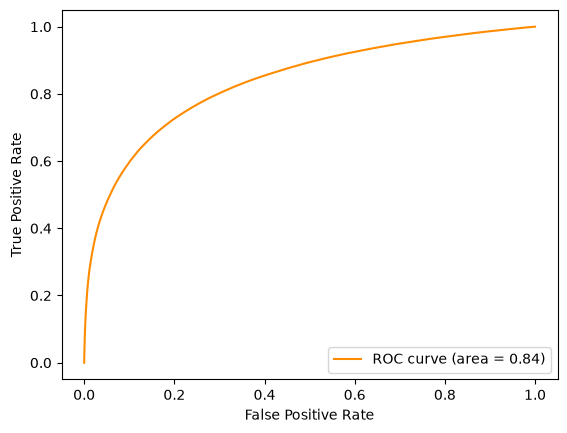

In [30]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_Test, Fisher.decision_function(X_Test))

roc_auc = auc(fpr, tpr)

plt.plot(fpr,tpr,color='darkorange',label='ROC curve (area = %0.2f)' % roc_auc)
plt.legend(loc="lower right")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.show()


#### Part a
TPR/FPR/ROC/AUC are one way of assessing the quality of a classifier. Read about [Precision and Recall](https://en.wikipedia.org/wiki/Precision_and_recall), [Accuracy](https://en.wikipedia.org/wiki/Accuracy_and_precision), and [F-score](https://en.wikipedia.org/wiki/F-score).

#### Part b
Look through [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html#) documentation. Using scikit-learn's tools, compute TPR, FPR, ROC, AUC, Precision, Recall, F1 score, and accuracy for the method you selected in Exercise 4c and each scenario. Make a nice table, which also includes the maximal significance. 


,N_S,N_B,TPR,FPR,AUC,Precision,Recall,F1,Accuracy,Significance
0,10,100,0.4584,0.0212,0.8669,0.9482,0.4584,0.618,0.7404,1.7708
1,100,1000,0.4584,0.0212,0.8669,0.9482,0.4584,0.618,0.7404,5.5998
2,1000,10000,0.4584,0.0212,0.8669,0.9482,0.4584,0.618,0.7404,17.7080
3,10000,100000,0.4584,0.0212,0.8669,0.9482,0.4584,0.618,0.7404,55.9976


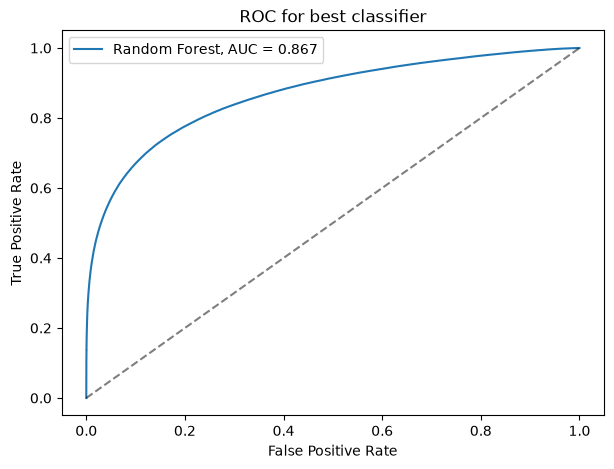

In [36]:
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score

y = y_Test.to_numpy()
fpr_curve, tpr_curve, _ = roc_curve(y, test_scores_best)
auc_value = roc_auc_score(y, test_scores_best)
rows = []
for result in scenario_results:
    ns = result["N_S"]
    nb = result["N_B"]
    cut = result["Cut"]
    predicted = (test_scores_best >= cut).astype(int)
    tpr = recall_score(y, predicted, zero_division=0)
    fpr = np.mean(predicted[y == 0])
    rows.append({
        "N_S": ns,
        "N_B": nb,
        "TPR": tpr,
        "FPR": fpr,
        "AUC": auc_value,
        "Precision": precision_score(y, predicted, zero_division=0),
        "Recall": tpr,
        "F1": f1_score(y, predicted, zero_division=0),
        "Accuracy": accuracy_score(y, predicted),
        "Significance": float(significance(tpr, fpr, ns, nb))
    })

metrics_table = pd.DataFrame(rows)
display(metrics_table.round(4))
plt.figure(figsize=(7, 5))
plt.plot(fpr_curve, tpr_curve, label=f"{best_name}, AUC = {auc_value:.3f}")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC for best classifier")
plt.legend()
plt.show()